In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/datascikhan/e-commerce-sales-and-customer-analytics/order_items.csv
/kaggle/input/datasets/datascikhan/e-commerce-sales-and-customer-analytics/customer_master.csv
/kaggle/input/datasets/datascikhan/e-commerce-sales-and-customer-analytics/ecommerce_sales_customer_analytics_150k.csv
/kaggle/input/datasets/datascikhan/e-commerce-sales-and-customer-analytics/dataset_statistics.csv
/kaggle/input/datasets/datascikhan/e-commerce-sales-and-customer-analytics/product_catalog.csv


In [2]:
df=pd.read_csv("/kaggle/input/datasets/datascikhan/e-commerce-sales-and-customer-analytics/order_items.csv")
df.head()

,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53


In [3]:
df=df.drop(columns=["order_id","product_id"],axis=1)
df.head()

,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12
1,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92
2,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84
3,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37
4,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53


In [4]:
df["profit"].max()

4045.1

In [5]:
df[
(df["discount_percentage"]>0.46)&(df["profit"]>700)
]

,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
2781,4,910.78,0.469793,1711.51,3643.12,367.01,5.27,2303.89,1470.52,828.10
229131,5,793.04,0.466480,1849.69,3965.20,401.95,3.15,2520.61,1724.95,792.51
352743,5,793.04,0.473124,1876.03,3965.20,417.83,3.33,2510.33,1724.95,782.05
359513,4,847.05,0.483480,1638.13,3388.20,332.51,4.56,2087.14,1366.88,715.70


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397569 entries, 0 to 397568
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   quantity             397569 non-null  int64  
 1   unit_price           397569 non-null  float64
 2   discount_percentage  397569 non-null  float64
 3   discount_amount      397569 non-null  float64
 4   gross_sales          397569 non-null  float64
 5   tax_amount           397569 non-null  float64
 6   shipping_cost        397569 non-null  float64
 7   net_sales            397569 non-null  float64
 8   product_cost         397569 non-null  float64
 9   profit               397569 non-null  float64
dtypes: float64(9), int64(1)
memory usage: 30.3 MB


In [7]:
df.describe()

,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
count,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000,397569.000000
mean,2.118792,245.189134,0.147059,89.667873,519.013550,46.183642,8.409010,483.938328,267.520046,208.009273
std,1.196276,251.035134,0.129986,190.637796,676.800478,71.072019,6.777155,615.430188,394.773555,266.477677
min,1.000000,6.310000,0.000000,0.000000,6.310000,0.260000,0.000000,5.350000,1.970000,-1260.280000
25%,1.000000,74.360000,0.048137,5.940000,122.000000,9.560000,3.370000,124.280000,52.960000,53.730000
50%,2.000000,164.970000,0.124253,26.340000,280.190000,22.550000,5.870000,271.100000,127.100000,121.660000
75%,3.000000,310.790000,0.199499,86.030000,643.560000,52.340000,12.460000,595.240000,314.310000,259.660000
max,5.000000,1482.950000,0.600000,3857.670000,7414.750000,1482.950000,36.460000,8897.700000,4968.150000,4045.100000


In [8]:
df.isnull().sum()

quantity               0
unit_price             0
discount_percentage    0
discount_amount        0
gross_sales            0
tax_amount             0
shipping_cost          0
net_sales              0
product_cost           0
profit                 0
dtype: int64

In [9]:
for i in df.columns:
    print(df[i].nunique())
    print("*"*50)

5
**************************************************
1164
**************************************************
343634
**************************************************
50505
**************************************************
5724
**************************************************
29348
**************************************************
2851
**************************************************
125944
**************************************************
5516
**************************************************
78190
**************************************************


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

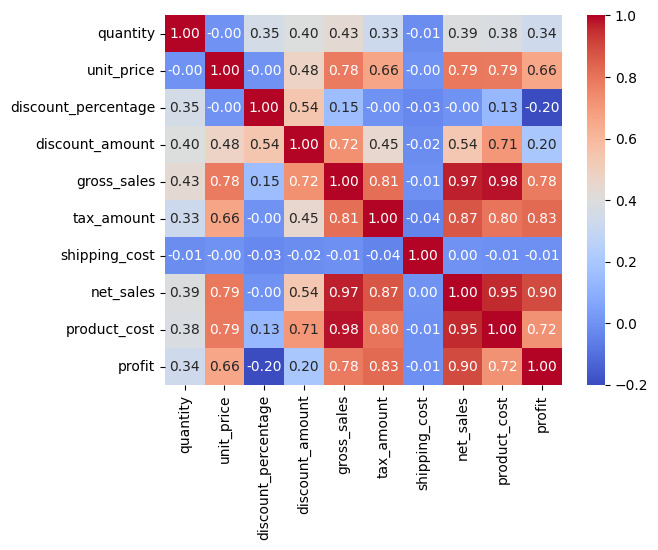

In [11]:
sns.heatmap(df.corr(),cmap="coolwarm",annot=True,fmt=".2f")
plt.show()

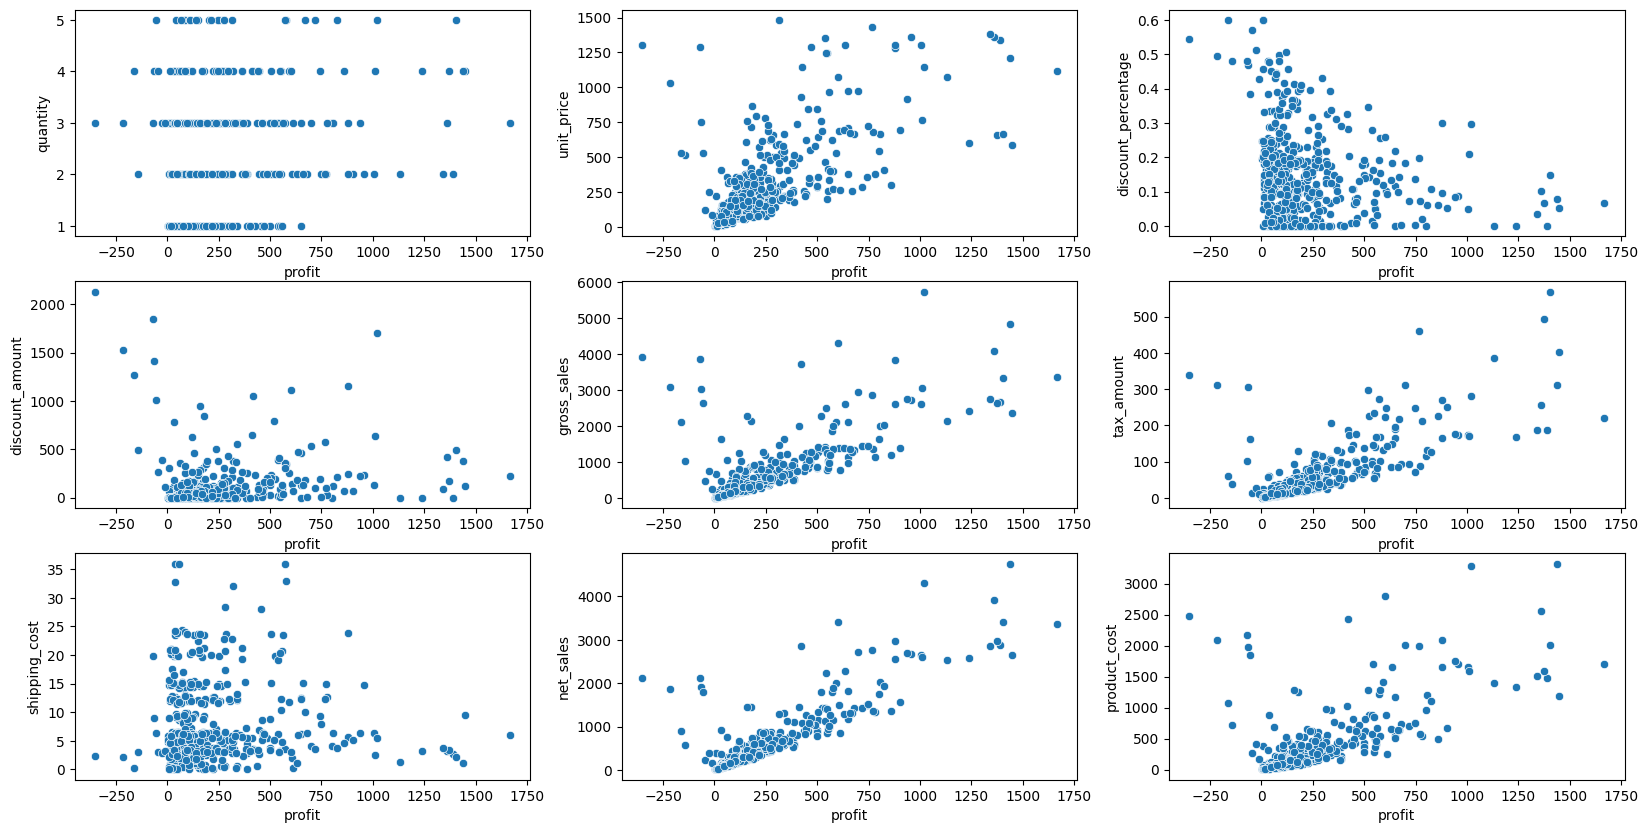

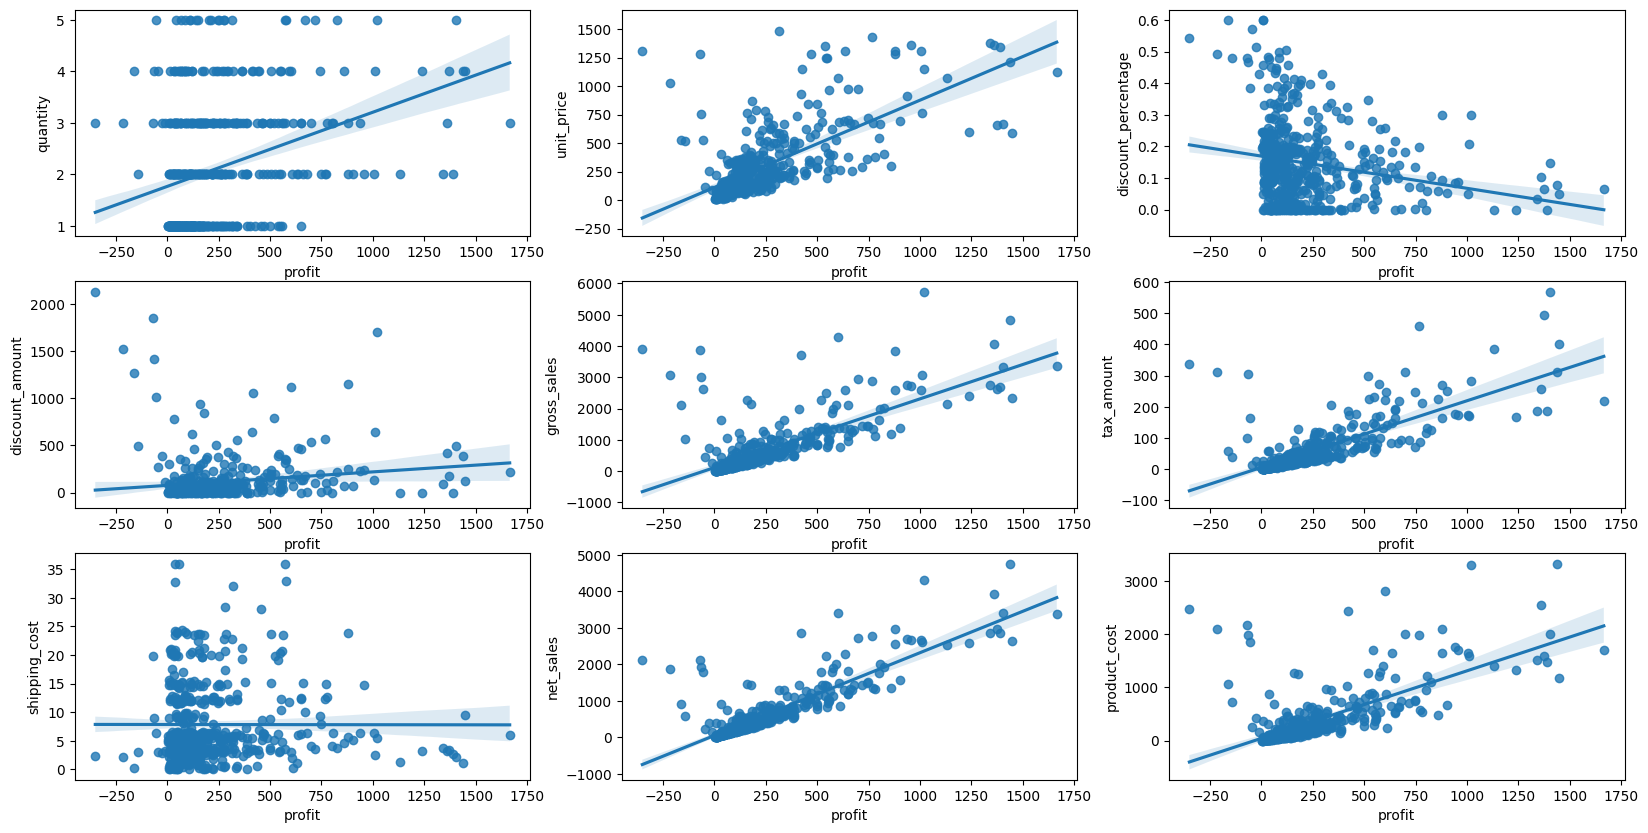

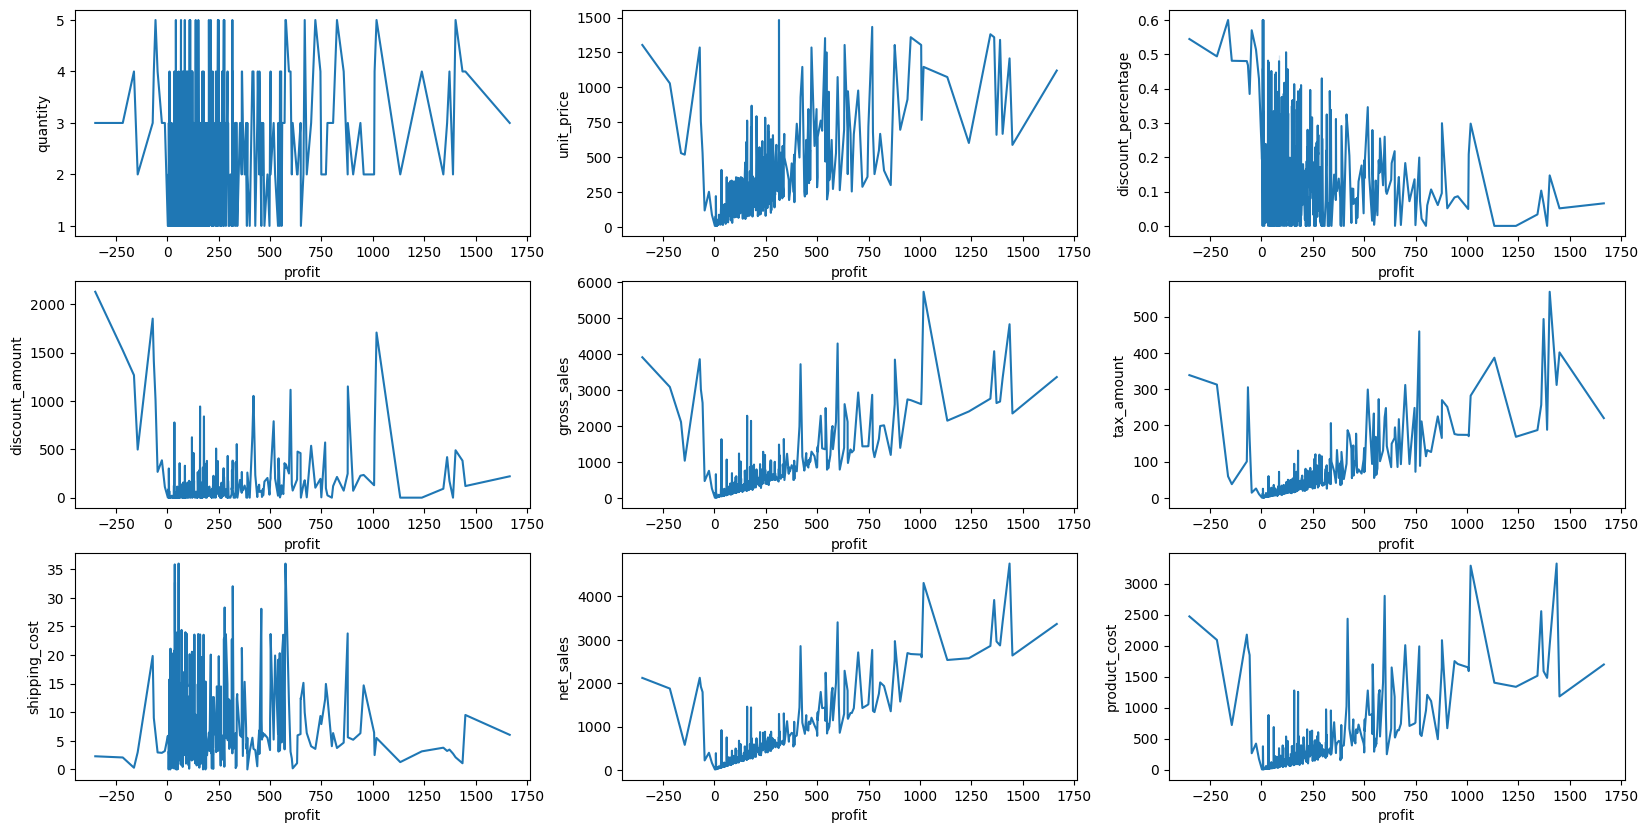

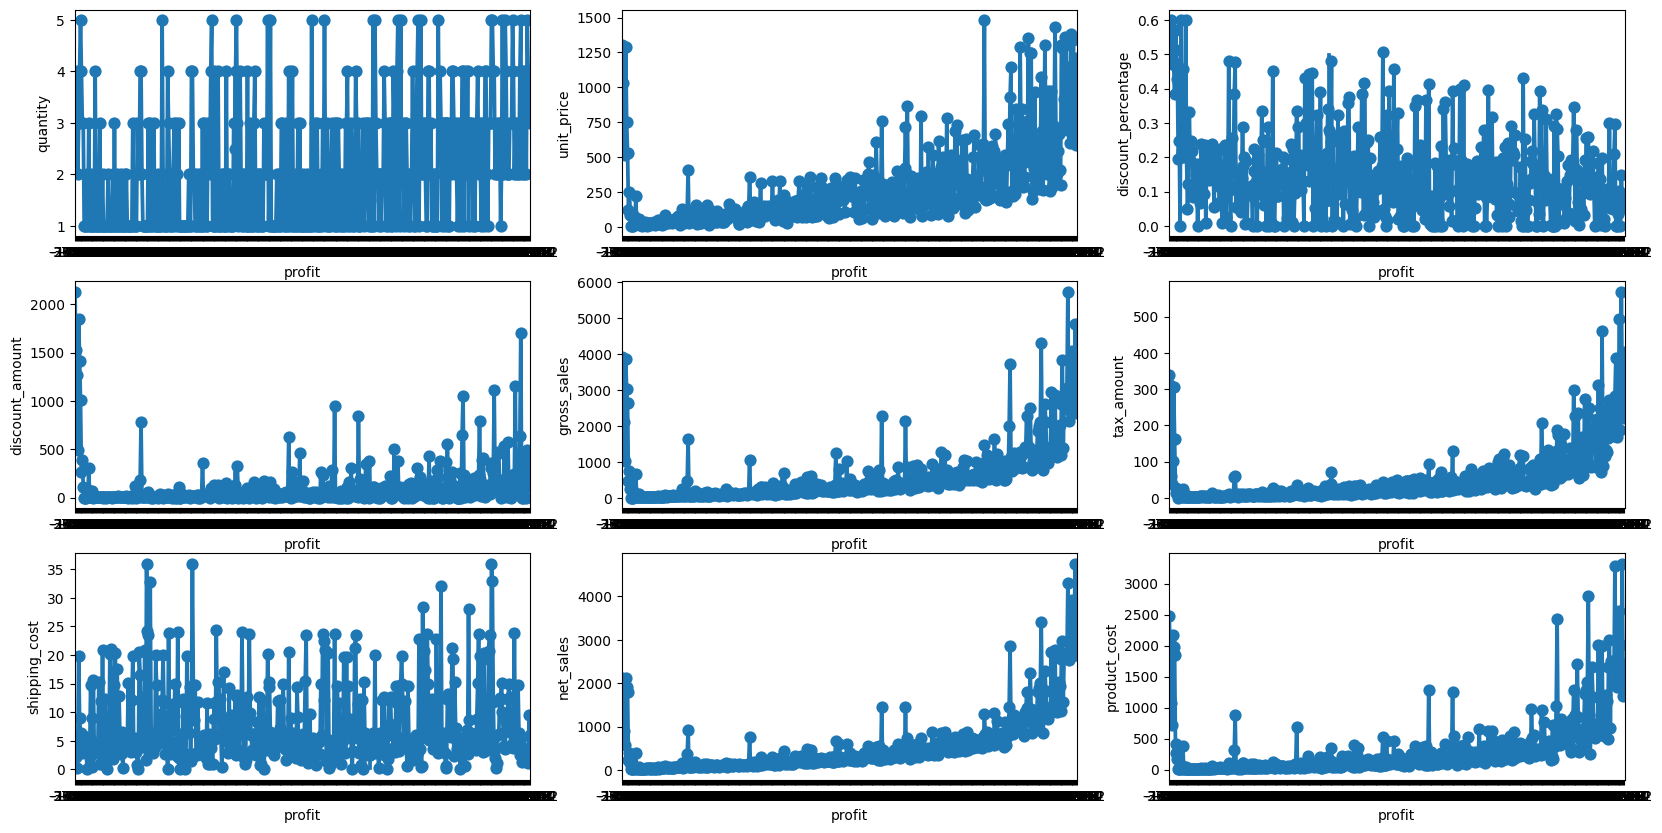

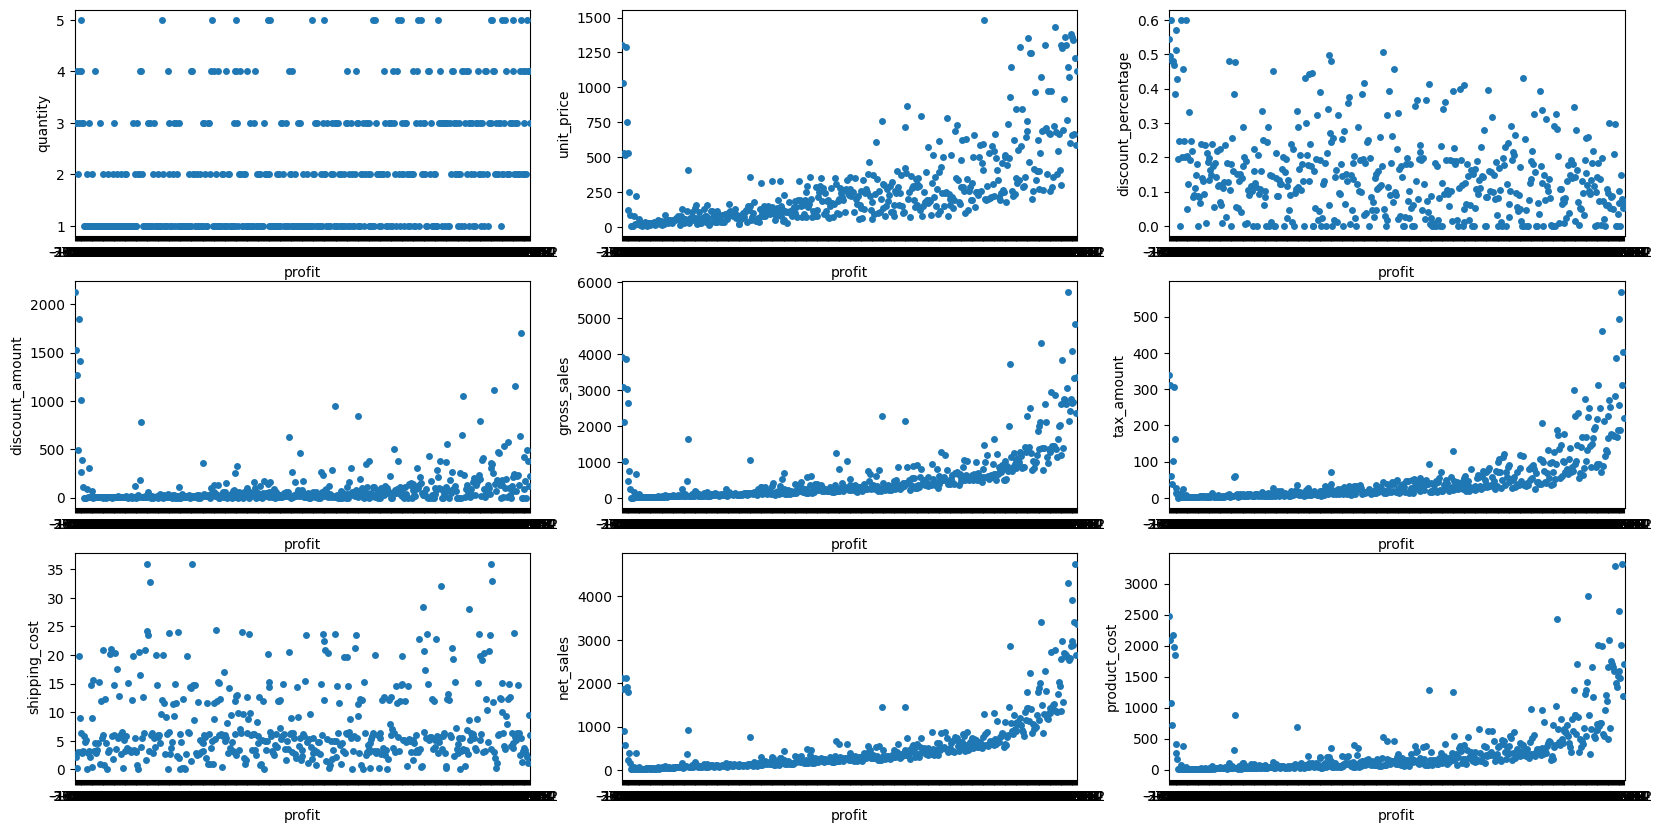

In [12]:
import warnings
warnings.filterwarnings("ignore")
grafic=["scatterplot","regplot","lineplot","pointplot","swarmplot"]
for m in grafic:
    fig=plt.figure(figsize=(20,10))
    say=1
    for i in df.columns:
        if i=="profit":
            continue
        fig.add_subplot(3,3,say)
        getattr(sns,m)(df.head(500),x="profit",y=i)
        say+=1
    plt.show()

In [13]:
data_cut = df.iloc[0:250 , :]

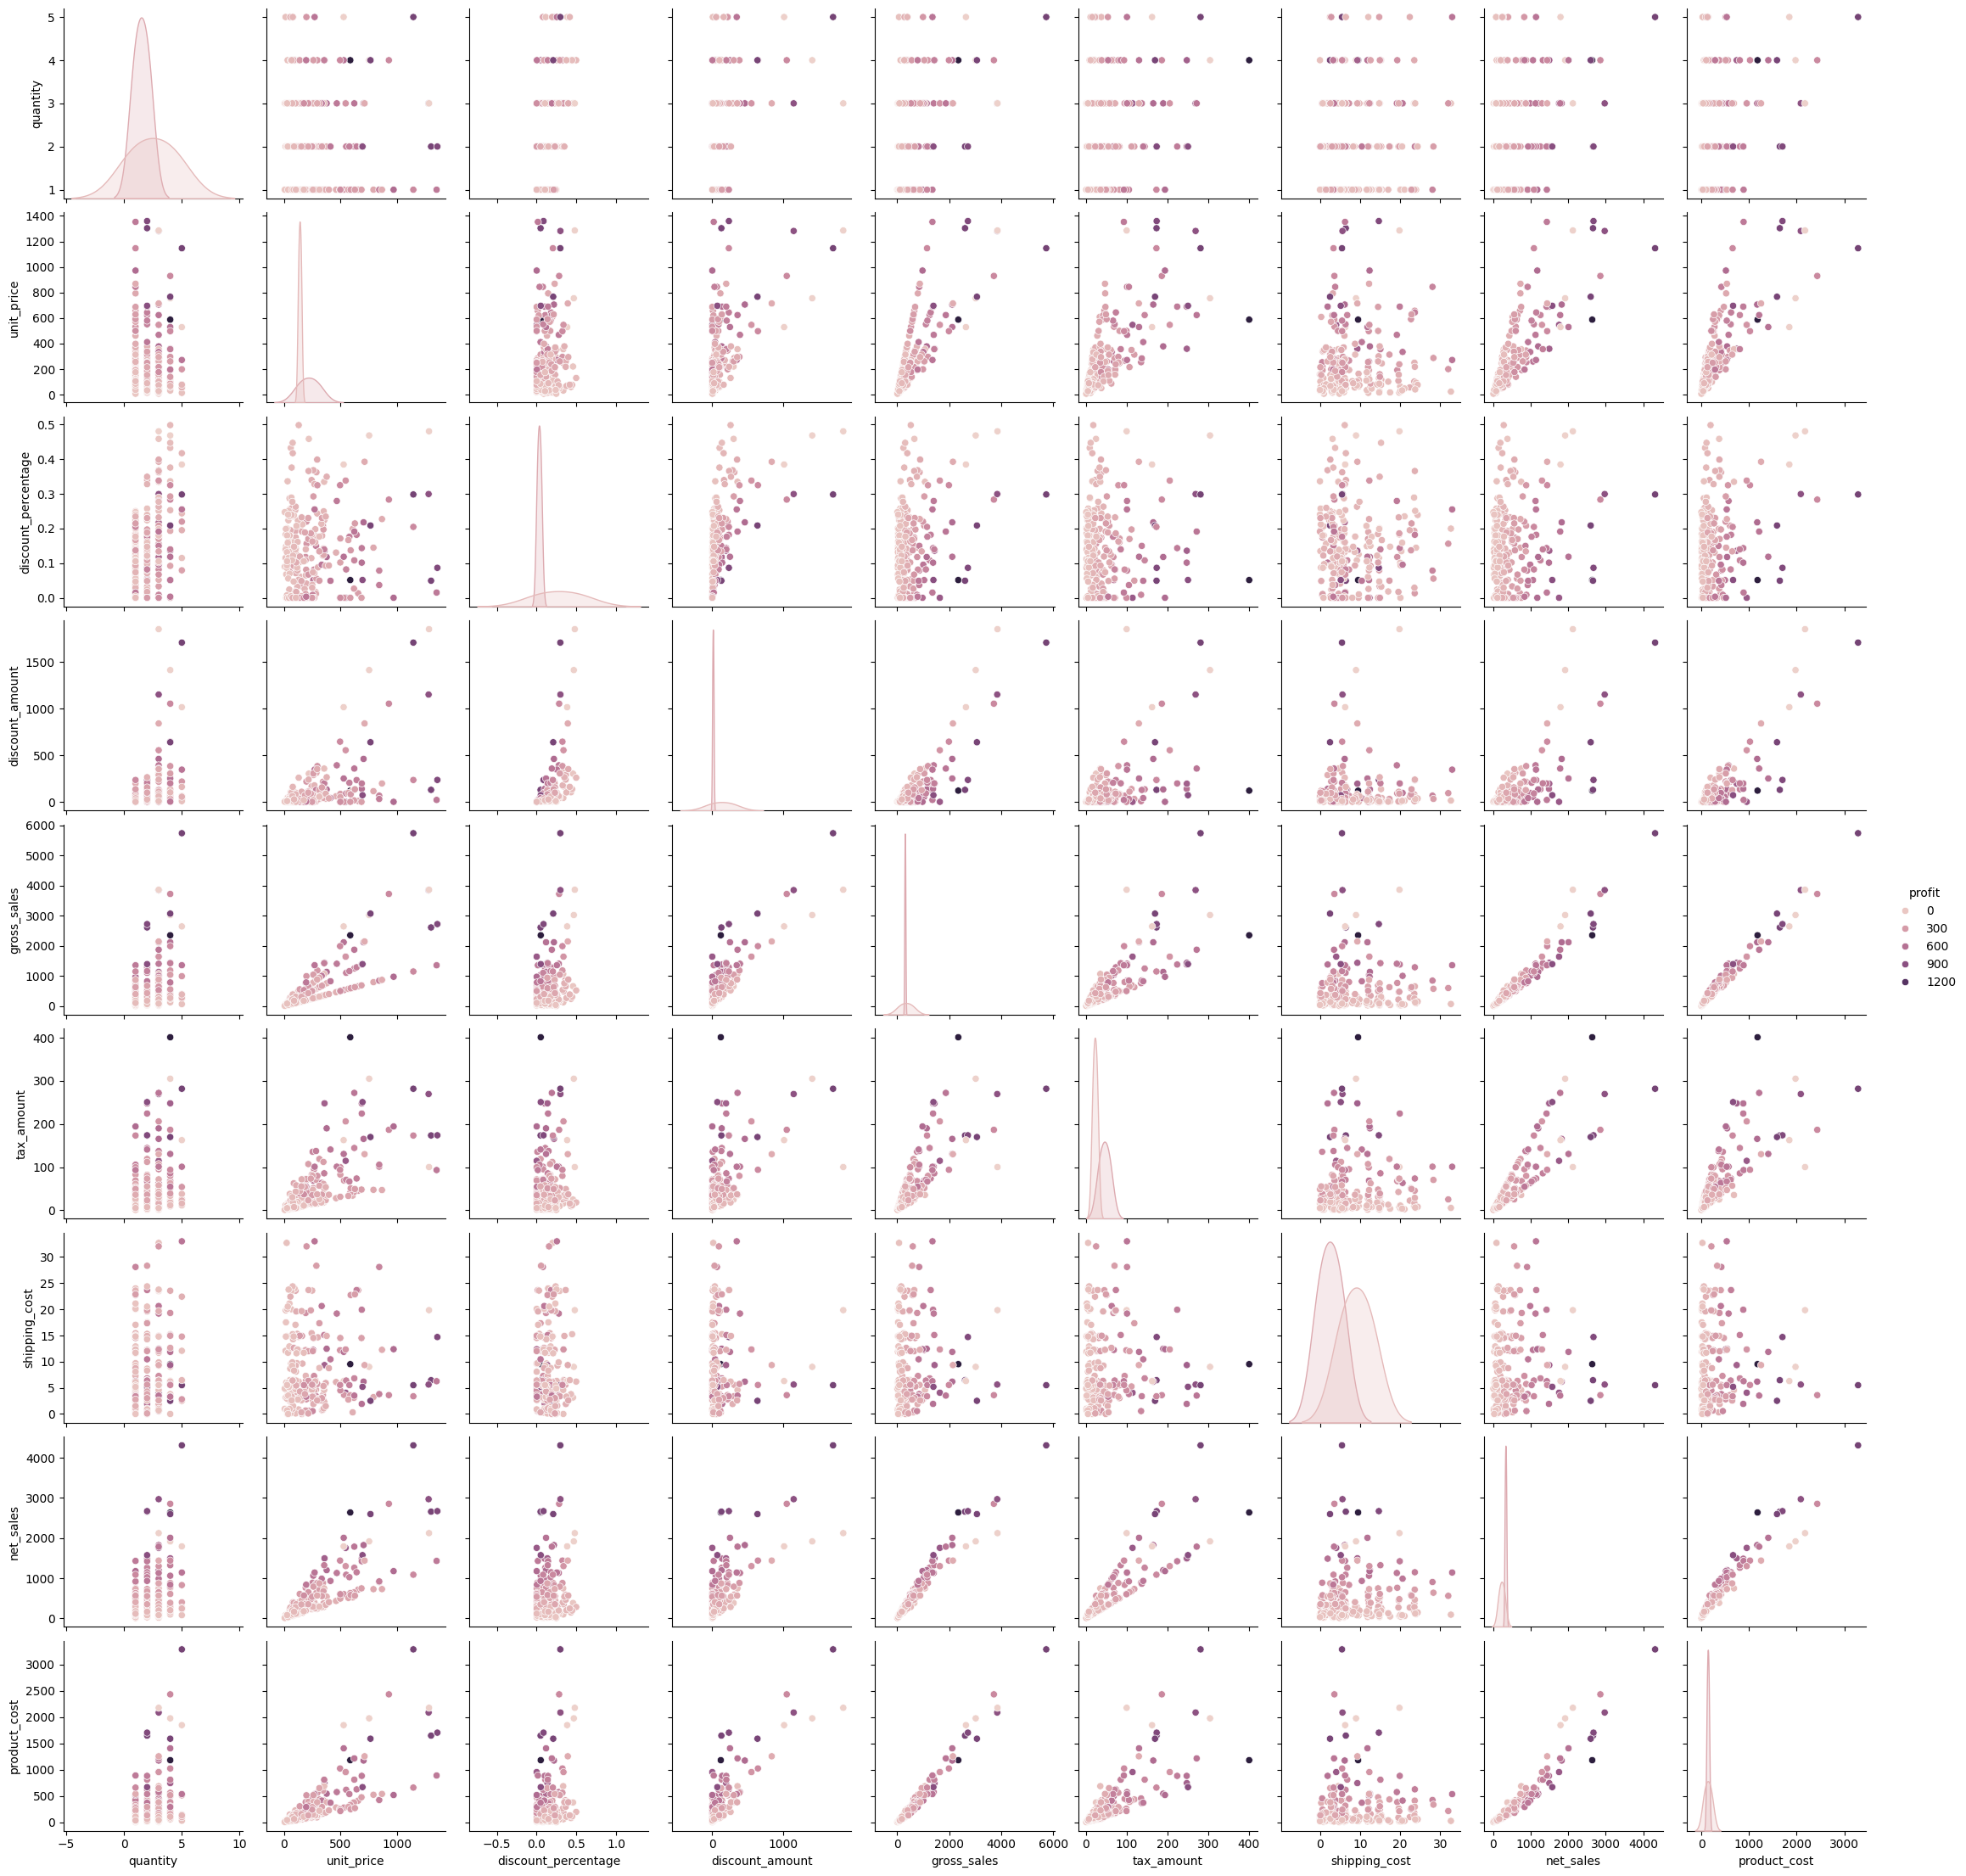

In [14]:
sns.pairplot(data = data_cut, hue = "profit")